# 01 · Order-book reconstruction (Stage 0.1–0.3)
**Microstructure Alpha · Binance USD-M ETHUSDT perpetual · 7–14 Sep 2026 (192 hourly L2 files)**

This notebook rebuilds the limit order book exactly from the hourly diff-depth files. It writes the **top-10 levels after every update batch** and an **audit log** that later notebooks depend on.

### How the data works (checked on 7 Sep, hour 06)
| Field | Meaning |
|---|---|
| `event_type = snapshot` | Full-depth book at the start of the file (about 37k levels). `final_update_id` = **L** (lastUpdateId). |
| `event_type = update` | One diff message per batch, every ~27 ms. Rows in a batch share `final_update_id` = **u**. |
| `first_update_id` U, `prev_final_update_id` **pu** | `pu` = the `u` of the previous message: the continuity chain. |
| `quantity` | **New absolute size** of the level. `0` removes it. It is *not* a change. |
| `transaction_time` | Matching-engine time (ms): the **research clock**. |
| `received_time` | Local capture time (ns), ~127 ms later: the **trading clock**. |

### Sync rules (Binance **futures**, not spot)
- Update IDs **skip between messages**: the next `U` is a median of ~143 above the previous `u`. So "U = L+1" is the wrong test; it produced a false "194-ID gap" earlier.
- After a snapshot, the stream is linked if **the first message has `pu == L`**. The documented fallback is `U ≤ L ≤ u` after dropping messages with `u < L`.
- Every later message must have **`pu ==` the previous `u`**. A break marks the book invalid until the next snapshot.

### What happens at each hour boundary
1. **Audit:** compare the replayed top 20 levels (the state at the previous file's last `u`) with the new file's snapshot (the state at `L`). If `L == prev_last_u`, they should match **exactly**.
2. **Choose the mode:** `snapshot_linked` (reset to the snapshot) → `continued` (keep the replayed book, if `pu` links to the previous file) → `snapshot_bracket` → `unsynced` (the hour is flagged invalid).

### Files with more than one snapshot (segments)
Some hours contain a **second snapshot in the middle**, for example when the recorder reconnected. Each file is split at every snapshot into **segments**, and every segment goes through the same audit and mode logic as an hour boundary. Update rows *before* the first snapshot form a `leading` segment: `continued` if their `pu` links to the book carried in from the previous file, `unsynced_no_snapshot` otherwise. Every book row carries a `seg` column.

### Two engines, one answer
| | Role | Code |
|---|---|---|
| **C++ book builder** | Production engine: writes the book files every later notebook uses | `cpp/` (CMake, MSVC) |
| **numba engine** | Independent reference: replays the same hour from the same parsed data | `ma_lib.BookBuilder` |

Both use integer ticks (0.01) and lots (0.001), parsed exactly from the strings with no floats, on a tick-indexed book with incrementally tracked best prices. The gate requires **identical output on every batch of every hour**. Two independent implementations that agree are a stronger acceptance test than either alone. Verified so far on 7 Sep hour 06 and on split-hour boundary tests (linked, continued, unsynced): every batch identical, and all 36 sync-log fields equal.

Per hour: parse about 1.5 s (Python, once), C++ replay about 0.1 s, numba replay about 0.1 s. All 192 hours take about 10–15 minutes.

**Requirements:** `pip install pyarrow pandas numpy numba matplotlib`. Keep `ma_lib.py` in the same folder as this notebook, and build the C++ program once (section 0).

## 0 · Build the C++ book builder (once, MSVC)
Open **"x64 Native Tools Command Prompt for VS 2022"** (Start menu), then:
```
cd <project>\cpp
cmake -S . -B build -G "Visual Studio 17 2022" -A x64
cmake --build build --config Release
ctest --test-dir build -C Release --output-on-failure
```
This produces `cpp\build\Release\book_builder.exe` and `test_book.exe`. If CMake says it can't find the generator, use `-G "Visual Studio 16 2019"` or `-G Ninja`. The program reads `.l2bin` files (exact integer rows written by `ma_lib.ingest_hour`). It carries the book between hours in a small state file holding only the non-empty levels.

In [1]:
# ===================== CONFIG — edit these paths =====================
from pathlib import Path
ROOT_DIR = Path(r"C:\microalpha_proj\Micro Alpha")            # folder that contains '7th sept', '8th sept', ... (any layout works)
OUT_DIR  = Path(r"C:\microalpha_proj\microoutput")
CPP_DIR  = Path.cwd().parent / "cpp" / "build" / "Release"   # where MSVC puts book_builder.exe (change if elsewhere)
DATES    = [f"2026-09-{d:02d}" for d in range(7, 15)]   # D1..D8
SYMBOL   = "ETHUSDT"
K_LEVELS = 10        # levels saved per side per batch
AUDIT_N  = 20        # levels compared at every snapshot audit
STRICT   = True      # stop if any of the 192 L2 files is missing
CROSS_CHECK = True   # also replay every hour with the numba engine and require identical output
# ===========================================================================

In [2]:
import sys, time, json, numpy as np, pandas as pd, matplotlib.pyplot as plt
sys.path.insert(0, str(Path.cwd()))
import ma_lib
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 60)
(OUT_DIR / 'book').mkdir(parents=True, exist_ok=True); (OUT_DIR / 'reports').mkdir(parents=True, exist_ok=True)
import subprocess, os
EXE = next((p for p in [CPP_DIR / 'book_builder.exe', CPP_DIR / 'book_builder'] if p.exists()), None)
TEST_EXE = next((p for p in [CPP_DIR / 'test_book.exe', CPP_DIR / 'test_book'] if p.exists()), None)
WORK = OUT_DIR / '_work'; WORK.mkdir(exist_ok=True)
print('ROOT_DIR exists:', ROOT_DIR.exists(), '| OUT_DIR:', OUT_DIR, '| book_builder:', EXE)
if EXE is None: raise FileNotFoundError(f'book_builder not found in {CPP_DIR}: build it first (section 0)')

ROOT_DIR exists: True | OUT_DIR: C:\microalpha_proj\microoutput | book_builder: c:\microalpha_proj\microalpha\cpp\build\Release\book_builder.exe


## 1 · Inventory: are all 192 L2 files and 8 trade files present and real?

In [3]:
inv = ma_lib.inventory(ROOT_DIR, SYMBOL)
inv_check = ma_lib.check_inventory(inv, DATES)
display(inv_check)
l2 = inv[(inv.kind == 'l2') & inv.date.isin(DATES)].sort_values(['date', 'hour']).reset_index(drop=True)
problems = []
if l2.duplicated(['date', 'hour']).any(): problems.append('duplicate hour files (e.g. "(1)" copies)')
if len(l2) != 24 * len(DATES): problems.append(f'{24*len(DATES) - len(l2)} L2 files missing')
if (l2.mb < 1).any(): problems.append('L2 files under 1 MB (likely OneDrive placeholders): ' + ', '.join(l2[l2.mb < 1].path))
print('L2 files found:', len(l2), '| trades files:', int((inv.kind == 'trades').sum()))
print('PROBLEMS:', problems or 'none')
if problems and STRICT: raise RuntimeError('Fix the inventory first (or set STRICT=False to run on what exists).')
inv.to_csv(OUT_DIR / 'reports' / '01_inventory.csv', index=False)

,date,l2_files,missing_hours,duplicate_hours,smallest_l2_mb,l2_total_mb,trades_files,trades_mb
0,2026-09-07,24,[],[],15.0,467,2,210.8
1,2026-09-08,24,[],[],13.7,508,1,215.9
2,2026-09-09,24,[],[],16.0,531,1,237.6
3,2026-09-10,24,[],[],14.8,533,1,230.8
4,2026-09-11,24,[],[],16.0,662,1,401.7
5,2026-09-12,24,[],[],12.1,348,1,87.2
6,2026-09-13,24,[],[],11.9,401,1,139.0
7,2026-09-14,24,[],[],16.7,610,1,294.5


L2 files found: 192 | trades files: 9
PROBLEMS: none


## 1b · Structure scan: which files have extra snapshots or updates before their snapshot?

In [4]:
scan = []
for _, r in l2.iterrows():
    b = ma_lib.snapshot_blocks(r.path)
    scan.append(dict(date=r.date, hour=int(r.hour), **b))
scan = pd.DataFrame(scan)
odd = scan[(scan.n_snapshots != 1) | (scan.leading_update_rows > 0)]
print(f'files with exactly one snapshot at the start: {len(scan) - len(odd)} / {len(scan)}')
display(odd)
scan.to_csv(OUT_DIR / 'reports' / '01_structure_scan.csv', index=False)

files with exactly one snapshot at the start: 19 / 192


,date,hour,n_snapshots,leading_update_rows,snapshot_rows,snapshot_times
14,2026-09-07,14,2,0,"[0, 2348195]","[14:00:00, 14:24:00.347000]"
15,2026-09-07,15,0,5861091,[],[]
16,2026-09-07,16,0,3848302,[],[]
17,2026-09-07,17,0,3784645,[],[]
18,2026-09-07,18,0,3360222,[],[]
...,...,...,...,...,...,...
182,2026-09-14,14,0,8152412,[],[]
183,2026-09-14,15,1,801603,[801603],[15:07:14.800000]
185,2026-09-14,17,2,0,"[0, 3176955]","[17:00:00, 17:37:02.623000]"
190,2026-09-14,22,2,0,"[0, 968071]","[22:00:00, 22:10:02.612000]"


In [5]:
import time
p = l2.path.iloc[60]
print('reading from:', p)
t = time.perf_counter(); d = ma_lib.load_l2_hour(p); t_read = time.perf_counter() - t
ST, LG = WORK / 't_state.bin', WORK / 't_log.csv'
for f in (ST, LG): f.unlink(missing_ok=True)
t = time.perf_counter(); df, info = ma_lib.run_cpp_hour(EXE, d, WORK, ST, LG, reset=True); t_cpp = time.perf_counter() - t
t = time.perf_counter(); dn, logs = ma_lib.BookBuilder().process_hour(d); t_nb = time.perf_counter() - t
t = time.perf_counter(); eq = ma_lib.compare_books(df, dn)['equal']; t_cmp = time.perf_counter() - t
t = time.perf_counter(); df.to_parquet(WORK / 't.parquet', compression='zstd', index=False); t_w = time.perf_counter() - t
print(f"read+parse {t_read:.1f}s | C++ total {t_cpp:.1f}s (ingest {info['ingest_s']}s, exe {info['cpp_s']}s) | "
      f"numba {t_nb:.1f}s | compare {t_cmp:.1f}s | write {t_w:.1f}s | equal={eq}")

reading from: C:\microalpha_proj\Micro Alpha\9th sept\ETHUSDT_orderbook_20260909_12.parquet
read+parse 4.3s | C++ total 2.8s (ingest 1.4s, exe 1.32s) | numba 0.0s | compare 0.0s | write 0.1s | equal=True


## 2 · Unit tests: C++ and numba on hand-made books where every answer is known

In [6]:
r = subprocess.run([str(TEST_EXE)], capture_output=True, text=True); print('C++  :', r.stdout.strip() or r.stderr)
assert r.returncode == 0, 'C++ unit tests failed'
_ = ma_lib.self_test()

C++  : all Book tests passed
engine self-test passed: snapshot load, level removal, improvement, best-price rescans, pu-chain break detection


## 3 · One hour first: compare with the reference numbers
Expected for **2026-09-07 hour 06**: mode `snapshot_linked`, 134,538 batches, 0 chain breaks, 0 crossed, latency median ≈ 127 ms, end of hour **2496.85 / 2496.86**.

In [7]:
probe = l2[(l2.date == '2026-09-07') & (l2.hour == 6)]
if len(probe):
    d = ma_lib.load_l2_hour(probe.path.iloc[0])
    pst, plog = WORK / 'probe_state.bin', WORK / 'probe_log.csv'
    for f in (pst, plog): f.unlink(missing_ok=True)
    df_cpp, info = ma_lib.run_cpp_hour(EXE, d, WORK, pst, plog, K_LEVELS, AUDIT_N, reset=True)
    b = ma_lib.BookBuilder(K=K_LEVELS, audit_n=AUDIT_N)
    df_probe, logs_probe = b.process_hour(d, '2026-09-07', 6)
    log_probe = logs_probe[0]
    print('C++:', info['stdout'], '| C++ vs numba:', ma_lib.compare_books(df_cpp, df_probe))
    show = ['mode','batches','chain_breaks','crossed_batches','invalid_batches','lat_med_ms','lat_p99_ms',
            'batch_gap_med_ms','end_best_bid','end_best_ask','parse_s','replay_s']
    display(pd.Series({k: log_probe[k] for k in show}))
    ok = (log_probe['mode'] == 'snapshot_linked' and log_probe['batches'] == 134538 and log_probe['crossed_batches'] == 0
          and log_probe['end_best_bid'] == 2496.85 and log_probe['end_best_ask'] == 2496.86)
    ok = ok and ma_lib.compare_books(df_cpp, df_probe)['equal']
    print('MATCHES REFERENCE' if ok else '>>> DOES NOT MATCH REFERENCE: stop and send me this output')
    del df_probe, df_cpp, d

C++: ETHUSDT_orderbook_20260907_06__s0  snapshot_linked  batches 134538  breaks 0  crossed 0  replay 149 ms | C++ vs numba: {'equal': True, 'mismatched_batches': 0, 'first_mismatch': None, 'mismatched_columns': []}


mode                snapshot_linked
batches                      134538
chain_breaks                      0
crossed_batches                   0
invalid_batches                   0
lat_med_ms               127.237793
lat_p99_ms               140.365188
batch_gap_med_ms               27.0
end_best_bid                2496.85
end_best_ask                2496.86
parse_s                         0.0
replay_s                        0.1
dtype: object

MATCHES REFERENCE


## 4 · Full run: all hours in time order, with one book carried across every boundary
Writes `OUT_DIR/book/<date>/book_<date>_<HH>.parquet` (one row per batch: `u, T, R, valid, n_rows, bp1..10, bq1..10, ap1..10, aq1..10`, with prices in ticks and sizes in lots) plus the sync log. Expect about 10–15 minutes.

In [8]:
STATE, CPP_LOG = WORK / 'book_state.bin', OUT_DIR / 'reports' / '01_sync_log_cpp.csv'
for f in (STATE, CPP_LOG): f.unlink(missing_ok=True)          # fresh, continuous run over all hours
ref = ma_lib.BookBuilder(K=K_LEVELS, audit_n=AUDIT_N)
py_logs, checks, t_start = [], [], time.time()
for i, r in l2.iterrows():
    d = ma_lib.load_l2_hour(r.path)                              # parse once
    df, info = ma_lib.run_cpp_hour(EXE, d, WORK, STATE, CPP_LOG, K_LEVELS, AUDIT_N)
    d_out = OUT_DIR / 'book' / r.date; d_out.mkdir(exist_ok=True)
    df.to_parquet(d_out / f'book_{r.date}_{int(r.hour):02d}.parquet', compression='zstd', index=False)
    eq = None
    if CROSS_CHECK:
        df_ref, logs = ref.process_hour(d, r.date, int(r.hour)); py_logs.extend(logs)
        cmp = ma_lib.compare_books(df, df_ref); eq = cmp['equal']
        checks.append(dict(date=r.date, hour=int(r.hour), **cmp)); del df_ref
    lines = [ln.split('  ', 1)[1] for ln in info['stdout'].splitlines()]
    print(f"{r.date} {int(r.hour):02d}  {' || '.join(lines)}  | C++==numba: {eq}  "
          f"({info['ingest_s'] + info['cpp_s']:.1f}s)" + ('' if eq in (True, None) else '  <-- MISMATCH'))
    del df, d
sync = pd.read_csv(CPP_LOG)
sync['segment'] = sync.file.str.extract(r'__s(\d+)$', expand=False).astype(int)
sync['file'] = sync.file.str.replace(r'__s\d+$', '', regex=True)
key = l2.assign(file=l2.path.map(lambda p: Path(p).stem))[['file', 'date', 'hour']]
sync = key.merge(sync, on='file', how='right')
print('segments per file:', sync.groupby('file').size().value_counts().sort_index().to_dict())
for c in ['first_pu_eq_prev_last_u', 'audit_touch_equal', 'audit_exact', 'u_strictly_increasing', 'T_non_decreasing']:
    sync[c] = sync[c].map({True: True, False: False, 'True': True, 'False': False})
sync.to_csv(OUT_DIR / 'reports' / '01_sync_log.csv', index=False)
engines = pd.DataFrame(checks)
if CROSS_CHECK:
    engines.to_csv(OUT_DIR / 'reports' / '01_engine_crosscheck.csv', index=False)
    # the two engines' sync logs must agree field by field too
    pl = pd.DataFrame(py_logs); diffs = []
    def norm(x):
        if x is None or (isinstance(x, float) and np.isnan(x)): return ''
        if isinstance(x, (bool, np.bool_)): return str(bool(x))
        if isinstance(x, (float, np.floating)) and float(x).is_integer(): return str(int(x))
        return str(x)
    for c in ['mode', 'batches', 'chain_breaks', 'invalid_batches', 'crossed_batches', 'audit_exact',
              'audit_bid_px_qty_equal', 'audit_ask_px_qty_equal', 'L_minus_prev_last_u', 'first_pu_eq_prev_last_u']:
        if c in pl:
            for j in range(len(sync)):
                a, b = norm(sync[c].iloc[j]), norm(pl[c].iloc[j])
                if a != b: diffs.append((sync.file.iloc[j], c, a, b))
    print('engine batch mismatches (hours):', int((~engines.equal).sum()), '| sync-log field differences:', diffs[:10] or 'none')
print(f'done in {(time.time() - t_start)/60:.1f} min')

2026-09-07 00  snapshot_linked  batches 134446  breaks 0  crossed 0  replay 180 ms  | C++==numba: True  (2.2s)
2026-09-07 01  snapshot_linked  batches 134417  breaks 0  crossed 0  replay 124 ms  | C++==numba: True  (1.4s)
2026-09-07 02  snapshot_linked  batches 134913  breaks 0  crossed 0  replay 554 ms  | C++==numba: True  (4.0s)
2026-09-07 03  snapshot_linked  batches 134660  breaks 0  crossed 0  replay 306 ms  | C++==numba: True  (11.9s)
2026-09-07 04  snapshot_linked  batches 134796  breaks 0  crossed 0  replay 364 ms  | C++==numba: True  (11.4s)
2026-09-07 05  snapshot_linked  batches 134816  breaks 0  crossed 0  replay 113 ms  | C++==numba: True  (12.4s)
2026-09-07 06  snapshot_linked  batches 134538  breaks 0  crossed 0  replay 130 ms  | C++==numba: True  (3.9s)
2026-09-07 07  snapshot_linked  batches 135327  breaks 0  crossed 0  replay 164 ms  | C++==numba: True  (1.6s)
2026-09-07 08  snapshot_linked  batches 134797  breaks 0  crossed 0  replay 110 ms  | C++==numba: True  (1.5s

## 5 · Boundary audit: does the replay agree with every hourly snapshot?
Each row is a boundary between consecutive files. Read it like this:
- `L_minus_prev_last_u == 0` and `audit_exact` → the replay and the snapshot describe the **same instant** and agree exactly. This is the strongest possible check.
- `L_minus_prev_last_u > 0` → the snapshot is later than the previous file's last message, so some messages fall between files. Small top-20 differences are expected; the size of the difference measures what was missed.
- `first_pu_eq_prev_last_u` → whether the message chain continues straight across the file boundary.

In [9]:
b_cols = ['date','hour','segment','mode','L_minus_prev_last_u','first_pu_eq_prev_last_u','audit_exact','audit_touch_equal',
          'audit_bid_px_qty_equal','audit_ask_px_qty_equal','first_U_minus_L']
bnd = sync.iloc[1:][b_cols] if len(sync) > 1 else pd.DataFrame(columns=b_cols)
display(bnd.head(30))
if len(bnd):
    print('boundaries:', len(bnd))
    print('mode counts:', sync['mode'].value_counts().to_dict())
    print('L - prev_last_u: ', bnd.L_minus_prev_last_u.describe().round(0).to_dict())
    print('chain continues across boundary:', int(bnd.first_pu_eq_prev_last_u.sum()), '/', len(bnd))
    print('exact top-20 audits:', int(bnd.audit_exact.sum()), '/', len(bnd), '| touch equal:', int(bnd.audit_touch_equal.sum()))
    print(f'mean top-20 levels equal (price & size): bid {bnd.audit_bid_px_qty_equal.mean():.1f}/{AUDIT_N}, '
          f'ask {bnd.audit_ask_px_qty_equal.mean():.1f}/{AUDIT_N}')

,date,hour,segment,mode,L_minus_prev_last_u,first_pu_eq_prev_last_u,audit_exact,audit_touch_equal,audit_bid_px_qty_equal,audit_ask_px_qty_equal,first_U_minus_L
1,2026-09-07,1,0,snapshot_linked,0.0,True,True,True,20.0,20.0,120.0
2,2026-09-07,2,0,snapshot_linked,0.0,True,True,True,20.0,20.0,86.0
3,2026-09-07,3,0,snapshot_linked,0.0,True,True,True,20.0,20.0,33.0
4,2026-09-07,4,0,snapshot_linked,0.0,True,True,True,20.0,20.0,157.0
5,2026-09-07,5,0,snapshot_linked,0.0,True,True,True,20.0,20.0,58.0
6,2026-09-07,6,0,snapshot_linked,0.0,True,True,True,20.0,20.0,195.0
7,2026-09-07,7,0,snapshot_linked,0.0,True,True,True,20.0,20.0,182.0
8,2026-09-07,8,0,snapshot_linked,0.0,True,True,True,20.0,20.0,192.0
9,2026-09-07,9,0,snapshot_linked,0.0,True,True,True,20.0,20.0,78.0
10,2026-09-07,10,0,snapshot_linked,0.0,True,True,True,20.0,20.0,65.0


boundaries: 203
mode counts: {'continued': 169, 'snapshot_linked': 23, 'snapshot_bracket': 12}
L - prev_last_u:  {'count': 34.0, 'mean': 2631620.0, 'std': 8970131.0, 'min': 0.0, '25%': 0.0, '50%': 0.0, '75%': 331871.0, 'max': 46756786.0}
chain continues across boundary: 22 / 203
exact top-20 audits: 22 / 203 | touch equal: 22
mean top-20 levels equal (price & size): bid 12.9/20, ask 12.9/20


## 6 · Day-level integrity summary and the gate

In [10]:
day = sync.groupby('date').agg(hours=('hour', 'nunique'), segments=('hour', 'size'), batches=('batches', 'sum'), chain_breaks=('chain_breaks', 'sum'),
        invalid_batches=('invalid_batches', 'sum'), crossed=('crossed_batches', 'sum'), one_sided=('one_sided_batches', 'sum'),
        linked_hours=('mode', lambda m: int((m == 'snapshot_linked').sum())),
        lat_med_ms=('lat_med_ms', 'median'), lat_p99_ms=('lat_p99_ms', 'max'), lat_max_ms=('lat_max_ms', 'max'),
        batch_gap_max_ms=('batch_gap_max_ms', 'max'), spread_med=('spread_med_ticks', 'median'),
        ordering_ok=('u_strictly_increasing', 'all'), time_ok=('T_non_decreasing', 'all'))
display(day)
gate = {
    'all 192 hours present': sync[['date', 'hour']].drop_duplicates().shape[0] == 24 * len(DATES),
    'zero crossed books in valid segments': int(sync.loc[sync.invalid_batches == 0, 'crossed_batches'].sum()) == 0,
    'zero pu-chain breaks': int(sync.chain_breaks.sum()) == 0,
    'every segment snapshot-linked or continued': bool(sync['mode'].isin(['snapshot_linked', 'continued']).all()),
    'u increasing & T non-decreasing everywhere': bool(sync.u_strictly_increasing.all() and sync.T_non_decreasing.all()),
    'C++ and numba identical on every batch': bool(CROSS_CHECK and len(engines) == len(l2) and engines.equal.all()),
}
for k, v in gate.items(): print(('PASS  ' if v else 'FAIL  ') + k)
day.to_csv(OUT_DIR / 'reports' / '01_day_summary.csv')

,hours,segments,batches,chain_breaks,invalid_batches,crossed,one_sided,linked_hours,lat_med_ms,lat_p99_ms,lat_max_ms,batch_gap_max_ms,spread_med,ordering_ok,time_ok
date,,,,,,,,,,,,,,,
2026-09-07,24,25,3227854,58,654,0,0,15,127.008423,159.610830,3853.286621,279,1.0,True,True
2026-09-08,24,25,3232889,20,31797,0,0,0,125.770264,224.179766,1677.009277,61,1.0,True,True
2026-09-09,24,25,3232359,11,9259,0,0,0,124.187012,950.422793,10405.460693,62,1.0,True,True
2026-09-10,24,25,3226068,20,69036,0,0,0,125.585938,352.844600,5197.909912,118,1.0,True,True
2026-09-11,24,25,3216074,20,20041,0,0,0,125.620850,495.168628,4301.021973,2591,1.0,True,True
2026-09-12,24,25,3197454,82,132167,0,0,0,127.648926,307.413281,1718.251465,60,1.0,True,True
2026-09-13,24,26,3192594,58,236492,0,0,0,129.297119,174.956621,1471.439941,53,1.0,True,True
2026-09-14,24,28,3195370,144,15147,0,0,8,127.018311,30745.283892,48804.166260,57,1.0,True,True


PASS  all 192 hours present
PASS  zero crossed books in valid segments
FAIL  zero pu-chain breaks
FAIL  every segment snapshot-linked or continued
PASS  u increasing & T non-decreasing everywhere
PASS  C++ and numba identical on every batch


## 7 · Plots: latency, update rate, spread and audit quality by hour

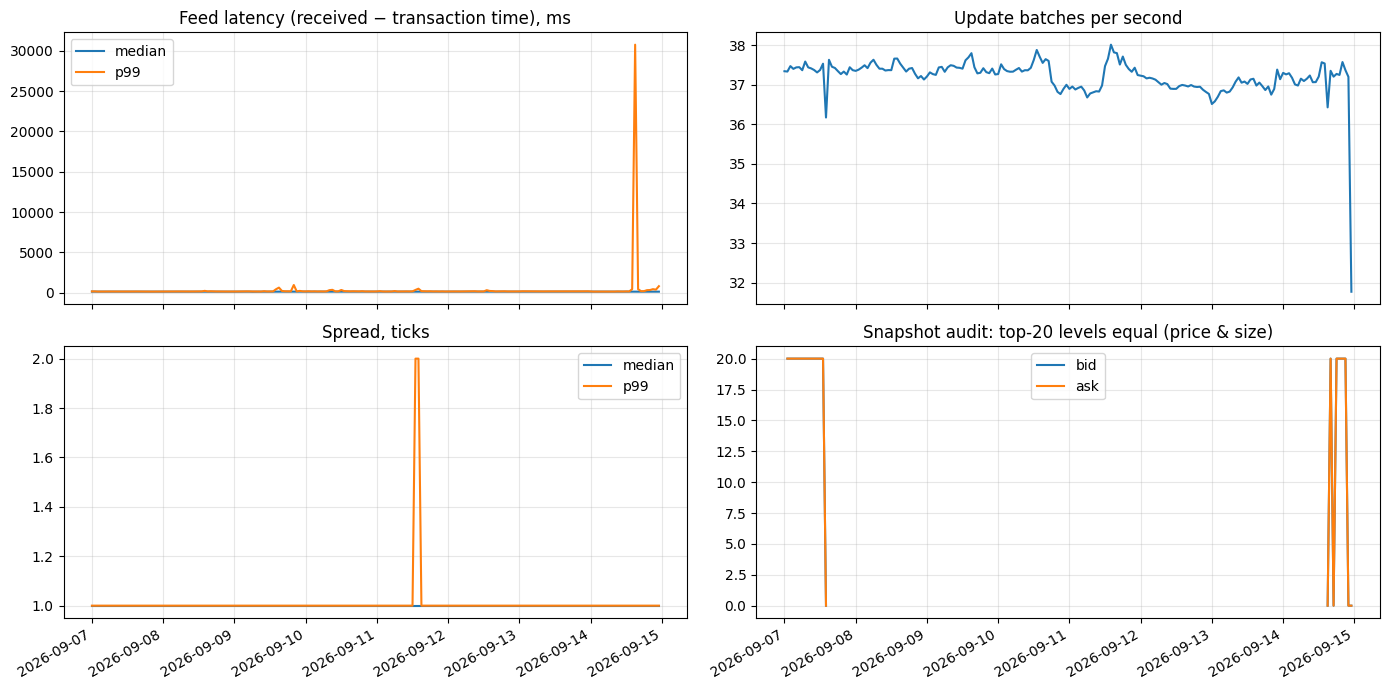

In [11]:
s = sync.groupby(['date', 'hour'], as_index=False).agg(lat_med_ms=('lat_med_ms', 'median'), lat_p99_ms=('lat_p99_ms', 'max'),
        batches=('batches', 'sum'), spread_med_ticks=('spread_med_ticks', 'median'), spread_p99_ticks=('spread_p99_ticks', 'max'),
        audit_bid_px_qty_equal=('audit_bid_px_qty_equal', 'min'), audit_ask_px_qty_equal=('audit_ask_px_qty_equal', 'min'))
s['t'] = pd.to_datetime(s.date) + pd.to_timedelta(s.hour, unit='h')
fig, ax = plt.subplots(2, 2, figsize=(14, 7), sharex=True)
ax[0,0].plot(s.t, s.lat_med_ms, label='median'); ax[0,0].plot(s.t, s.lat_p99_ms, label='p99'); ax[0,0].set_title('Feed latency (received − transaction time), ms'); ax[0,0].legend()
ax[0,1].plot(s.t, s.batches / 3600); ax[0,1].set_title('Update batches per second')
ax[1,0].plot(s.t, s.spread_med_ticks, label='median'); ax[1,0].plot(s.t, s.spread_p99_ticks, label='p99'); ax[1,0].set_title('Spread, ticks'); ax[1,0].legend()
if 'audit_bid_px_qty_equal' in s:
    ax[1,1].plot(s.t, s.audit_bid_px_qty_equal, label='bid'); ax[1,1].plot(s.t, s.audit_ask_px_qty_equal, label='ask')
    ax[1,1].set_ylim(-1, AUDIT_N + 1); ax[1,1].legend()
ax[1,1].set_title(f'Snapshot audit: top-{AUDIT_N} levels equal (price & size)')
for a in ax.flat: a.grid(alpha=.3)
fig.autofmt_xdate(); plt.tight_layout(); fig.savefig(OUT_DIR / 'reports' / '01_sync_plots.png', dpi=110); plt.show()

## 8 · Summary file to send back

In [12]:
lines = ['# 01 · Book reconstruction: summary', '', f'files: {len(l2)} hours, {len(sync)} segments, {int(sync.batches.sum()):,} batches', '']
lines += [('PASS ' if v else 'FAIL ') + k for k, v in gate.items()]
if len(bnd):
    lines += ['', f'boundaries: {len(bnd)}; chain continues across boundary: {int(bnd.first_pu_eq_prev_last_u.sum())}',
              f'exact audits: {int(bnd.audit_exact.sum())}; touch equal: {int(bnd.audit_touch_equal.sum())}',
              f'L - prev_last_u: {bnd.L_minus_prev_last_u.describe().round(0).to_dict()}',
              f"modes: {sync['mode'].value_counts().to_dict()}"]
lines += ['', f'latency median of hourly medians: {sync.lat_med_ms.median():.1f} ms; worst p99: {sync.lat_p99_ms.max():.1f} ms; max {sync.lat_max_ms.max():.0f} ms',
          f'levels outside price range ignored: {int(sync.out_of_range_levels.sum())}',
          f'C++ vs numba: {int(engines.equal.sum()) if CROSS_CHECK else "-"} / {len(l2)} hours identical',
          f'files with extra snapshots / leading updates: {len(odd)}']
(OUT_DIR / 'reports' / '01_summary.md').write_text('\n'.join(lines)); print('\n'.join(lines))
print('\nSend me: reports/01_summary.md, 01_sync_log.csv, 01_sync_plots.png, 01_engine_crosscheck.csv, 01_structure_scan.csv')

# 01 · Book reconstruction: summary

files: 192 hours, 204 segments, 25,720,662 batches

PASS all 192 hours present
PASS zero crossed books in valid segments
FAIL zero pu-chain breaks
FAIL every segment snapshot-linked or continued
PASS u increasing & T non-decreasing everywhere
PASS C++ and numba identical on every batch

boundaries: 203; chain continues across boundary: 22
exact audits: 22; touch equal: 22
L - prev_last_u: {'count': 34.0, 'mean': 2631620.0, 'std': 8970131.0, 'min': 0.0, '25%': 0.0, '50%': 0.0, '75%': 331871.0, 'max': 46756786.0}
modes: {'continued': 169, 'snapshot_linked': 23, 'snapshot_bracket': 12}

latency median of hourly medians: 126.6 ms; worst p99: 30745.3 ms; max 48804 ms
levels outside price range ignored: 2132
C++ vs numba: 192 / 192 hours identical
files with extra snapshots / leading updates: 173

Send me: reports/01_summary.md, 01_sync_log.csv, 01_sync_plots.png, 01_engine_crosscheck.csv, 01_structure_scan.csv
